In [2]:
## HW4 Setup ##

## Always start from Colab root ##
setwd("/content")

## GitHub information ##
user_name <- "shahrukh-malikk"
repo_name <- "STAT-7110-Quality-Control"

repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Clone only if the repository is not already present ##
repo_path <- file.path("/content", repo_name)

if (!dir.exists(repo_path)) {
  system(paste("git clone", repo_address, repo_path))
} else {
  print("Repository already cloned to Colab.")
}

## Go directly to HW4 ##
setwd("/content/STAT-7110-Quality-Control/Assignments/HW4")

## Install qcc if needed ##
if (!requireNamespace("qcc", quietly = TRUE)) {
  install.packages("qcc")
}

## Load libraries ##
library(tidyverse)
library(readxl)
library(qcc)

## Confirm setup ##
getwd()
list.files()

[1] "Repository already cloned to Colab."


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



[1] "/content/STAT-7110-Quality-Control/Assignments/HW4"

[1] "Counselling_PhaseI.xlsx"  "Counselling_PhaseII.xlsx"
[3] "STAT-7110-HW4.ipynb"

## Homework 4 - Analysis Using Hotelling's $T^2$ and Multiple Stream Process Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: November 20, 2026 via D2L**

## Instructions:

You are the director of The Owl's Nest, a psychological services program at a local university that employs a team of four Clinical Psychology PhD students to offer counseling services to the campus community at a steep discount. When a new client comes in, they commit to biweekly sessions for at least one semester. At the start of each session, the client completes a brief survey assessing depressive symptoms using Likert-scale items (e.g., "How much do you agree with this statement, on a scale from 1 (strongly disagree) to 5 (strongly agree)?"). The total score ranges from 20 to 100, with higher scores indicating more severe depressive symptoms.

If a counselor's client scores begin trending upward over time, that may indicate a need for you, as the director, to step in -- whether by providing additional training and supervision, or by referring a client to a higher level of care. Because all four counselors work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals), you suspect their clients' scores may be correlated with one another from week to week, rather than behaving as four completely independent processes.

To monitor this, you perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

## Key Specifications

| Quantity | Value |
|---|---|
| Quality characteristic | Total depressive-symptom survey score (20-100 scale) |
| Number of counselors (streams) | 4 |
| Clients sampled per counselor per week (n) | 5 |
| Phase I weeks (m) | 16 (fall semester) |
| Phase II weeks (m) | 16 (spring semester) |
| Control Chart for Each Stream design value | $L = 3.46$ |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

### Q2: Identify the quality characteristic being monitored, and classify its measurement scale. Why might it be reasonable to suspect that the four counselors' weekly scores are correlated with one another, rather than fully independent?

### Q3: Given your answer to Q2, briefly explain why it might be reasonable to treat this scenario as a **multivariate process** (suggesting a Hotelling's $T^2$ chart) rather than a **multiple stream process** (suggesting the Control Chart for Each Stream technique). Under what different assumption would the opposite framing make more sense?

## Analyze

### Q4: Read the Phase I data (`Counselling_PhaseI.xlsx`) into R as a list, one data frame per counselor (HINT: use `qcc::mqcc`, and make sure to remove the `Week` column from each data frame, possibly using `lapply`). Construct a Phase I Hotelling's $T^2$ chart. Do we have evidence of statistical control? Why or why not?

#ANSWERS

Q1

The purpose is to monitor weekly depressive-symptom scores across the four counselors. Phase I establishes whether the fall semester provides a stable baseline. Phase II checks whether the spring semester departs from that baseline, so the director can investigate changes and provide appropriate support. A stable process is predictable under the model; stability alone does not establish effective treatment or acceptable symptom levels.

Q2

We’re monitoring each clients total depression survey score, which ranges from 20 to 100. A higher score means more severe symptoms. We can treat the total as approximately interval-scale data, meaning the difference between scores is meaningful.The counselors weekly scores could be related because they work in the same setting and share training and supervision. Their clients also deal with similar pressures. For example, finals could increase stress across campus, causing scores to rise for several counselors at the same time.

Q3

A multivariate approach makes sense because the counselors weekly scores may move together due to shared factors, such as exam stress. Hotellings T-SQUARE chart lets us monitor all four counselors together while accounting for those relationships.
A multiple stream approach would make more sense if we assumed the counselors scores were independent ,that a change in one counselors scores had no connection to changes in the others. Under that assumption, we could monitor each counselor separately.

In [6]:

## Q4.1 Inspect Phase I Workbook ##

excel_sheets("/content/STAT-7110-Quality-Control/Assignments/HW4/Counselling_PhaseI.xlsx")

[1] "Counselor1" "Counselor2" "Counselor3" "Counselor4"

In [11]:
## Q4.1 Read and Prepare Phase I Data ##

phase1 <- lapply(
  excel_sheets("/content/STAT-7110-Quality-Control/Assignments/HW4/Counselling_PhaseI.xlsx"),
  function(sheet) {
    read_excel("/content/STAT-7110-Quality-Control/Assignments/HW4/Counselling_PhaseI.xlsx", sheet = sheet) |>
      select(-Week)
  }
)

names(phase1) <- excel_sheets("/content/STAT-7110-Quality-Control/Assignments/HW4/Counselling_PhaseI.xlsx")

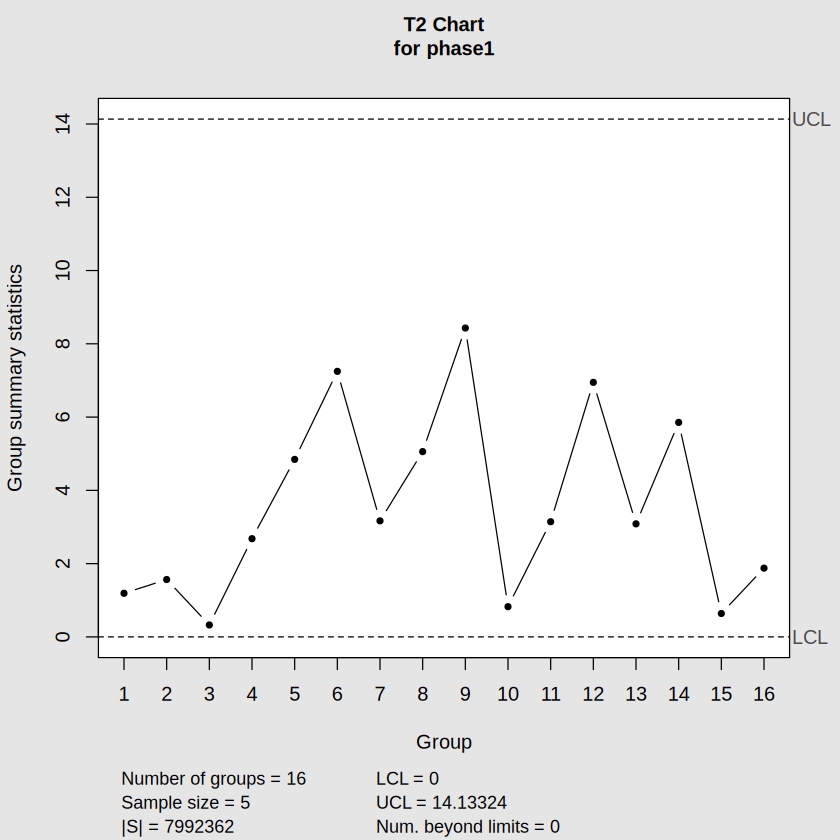

In [12]:
# Q4 Code ##

phase1_t2 <- mqcc(
  phase1,
  type = "T2",
  plot = TRUE
)


Yes, the PhaseI process appears to be in statistical control. All 16 weekly TSQUARE values are below the upper control limit of about 14.13. Since none of the points falls outside the limits, the chart gives us no reason to suspect an unusual change during the fall semester.

### Q5: Report the sample mean vector and sample variance-covariance matrix from Q4.

In [14]:
## Q5 Code
### Sample mean vector
phase1_t2$center



Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975

In [15]:
# Sample variance-covariance matrix
phase1_t2$cov

,Counselor1,Counselor2,Counselor3,Counselor4
Counselor1,64.94685,25.20394,18.73784,28.36822
Counselor2,25.20394,63.96758,30.76070,26.36930
Counselor3,18.73784,30.76070,67.29034,14.95226
Counselor4,28.36822,26.36930,14.95226,60.67095


### Q6: Read the Phase II data (`Counselling_PhaseII.xlsx`) into R the same way. Using the mean vector and covariance matrix from Q5, construct a Phase II Hotelling's $T^2$ chart. Do we still have evidence of statistical control? If not, generate individual univariate Shewhart $\bar{X}$ and $s$ charts (using the appropriate mean and standard deviation from Phase I) to determine which counselor(s) may have out-of-control scores.

In [16]:
## Q6 Code ##
## Q6.1 Read and Prepare Phase II Data ##

phase2 <- lapply(
  excel_sheets("/content/STAT-7110-Quality-Control/Assignments/HW4/Counselling_PhaseII.xlsx"),
  function(sheet) {
    read_excel("/content/STAT-7110-Quality-Control/Assignments/HW4/Counselling_PhaseII.xlsx", sheet = sheet) |>
      select(-Week)
  }
)

names(phase2) <- excel_sheets("/content/STAT-7110-Quality-Control/Assignments/HW4/Counselling_PhaseII.xlsx")

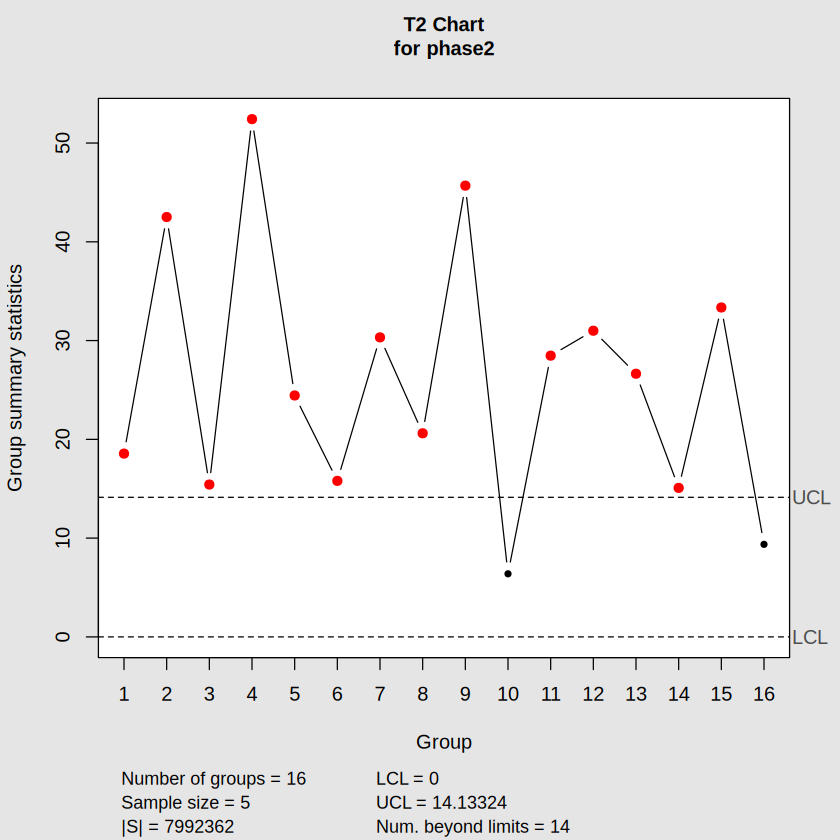

In [17]:
phase2_t2 <- mqcc(
  phase2,
  type = "T2",
  center = phase1_t2$center,
  cov = phase1_t2$cov,
  plot = TRUE
)

In [18]:
phase1_means <- phase1_t2$center
phase1_sds <- sqrt(diag(phase1_t2$cov))

phase1_means
phase1_sds

Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975

Counselor1 Counselor2 Counselor3 Counselor4 
  8.058961   7.997973   8.203069   7.789156

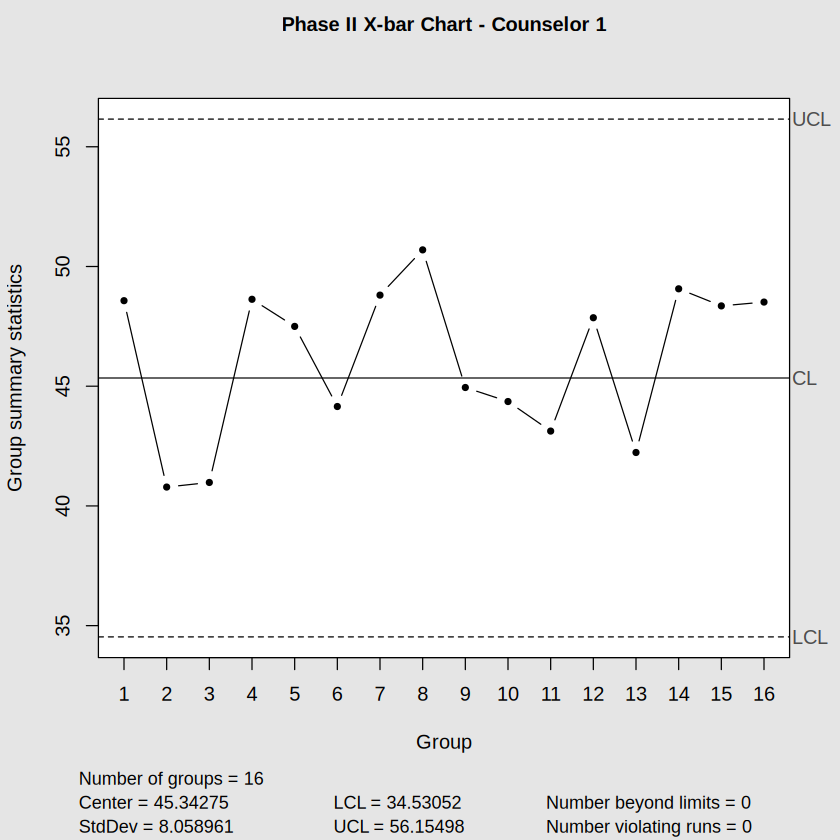

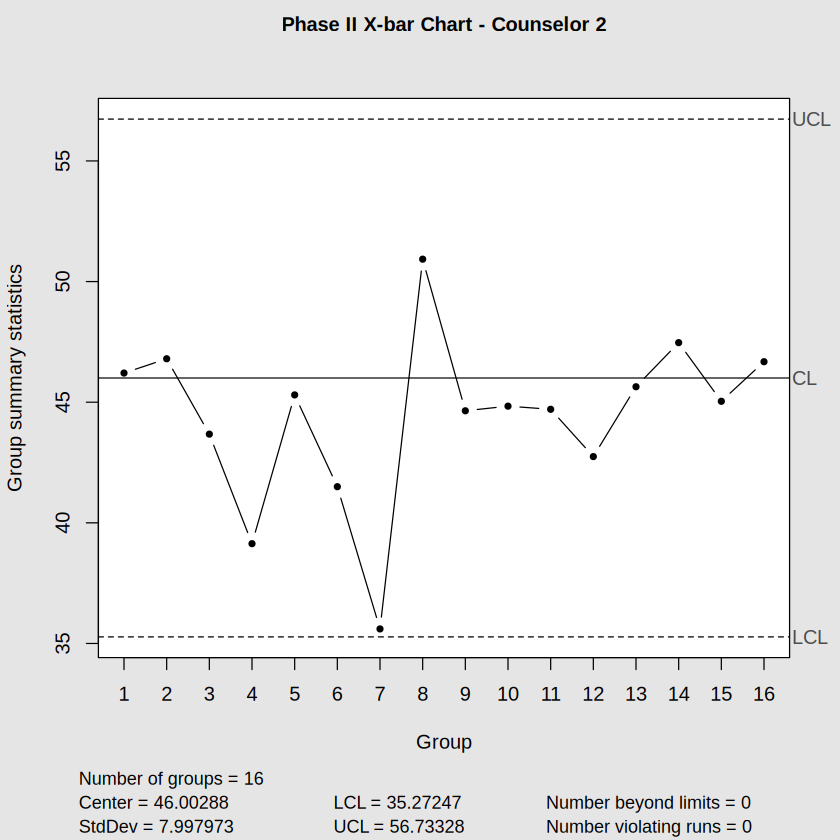

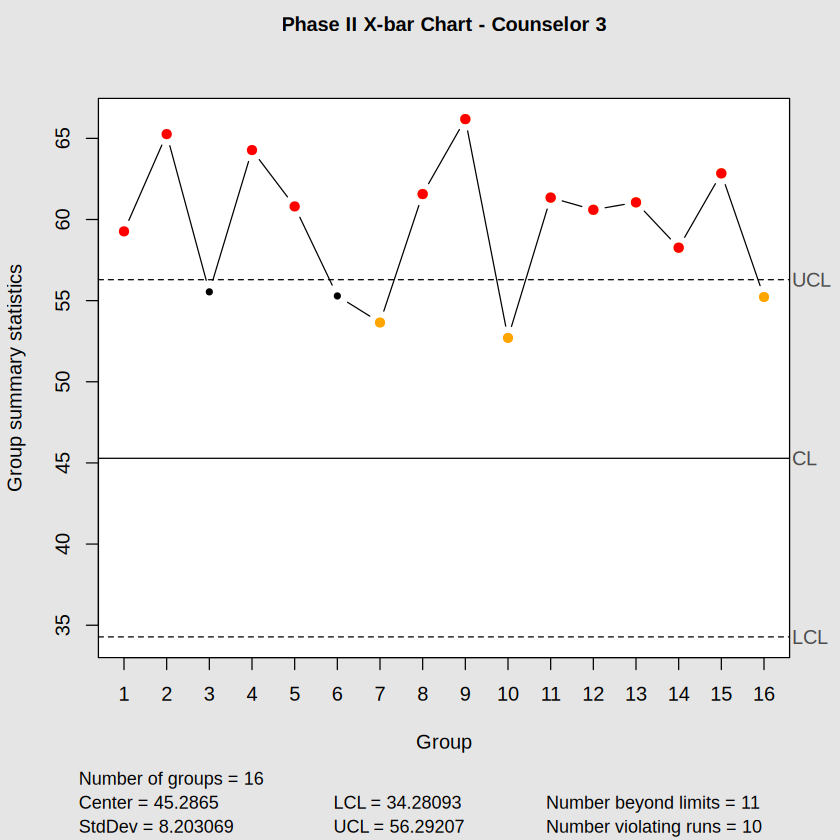

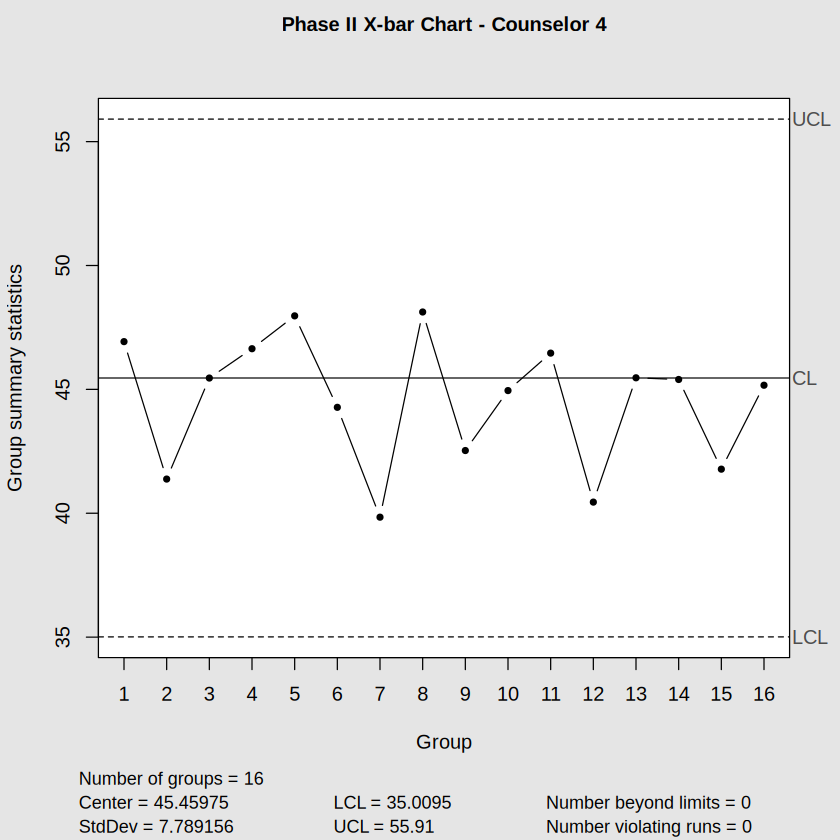

In [26]:
for (i in 1:4) {

  ## X-bar chart ##
  qcc(
    phase2[[i]],
    type = "xbar",
    center = phase1_means[i],
    std.dev = phase1_sds[i],
    title = paste("Phase II X-bar Chart - Counselor", i)
  )


}

In [27]:
# Calculate the Phase I center for each S chart
n <- ncol(phase1[[1]])

c4 <- sqrt(2 / (n - 1)) *
  gamma(n / 2) / gamma((n - 1) / 2)

phase1_s_centers <- c4 * phase1_sds

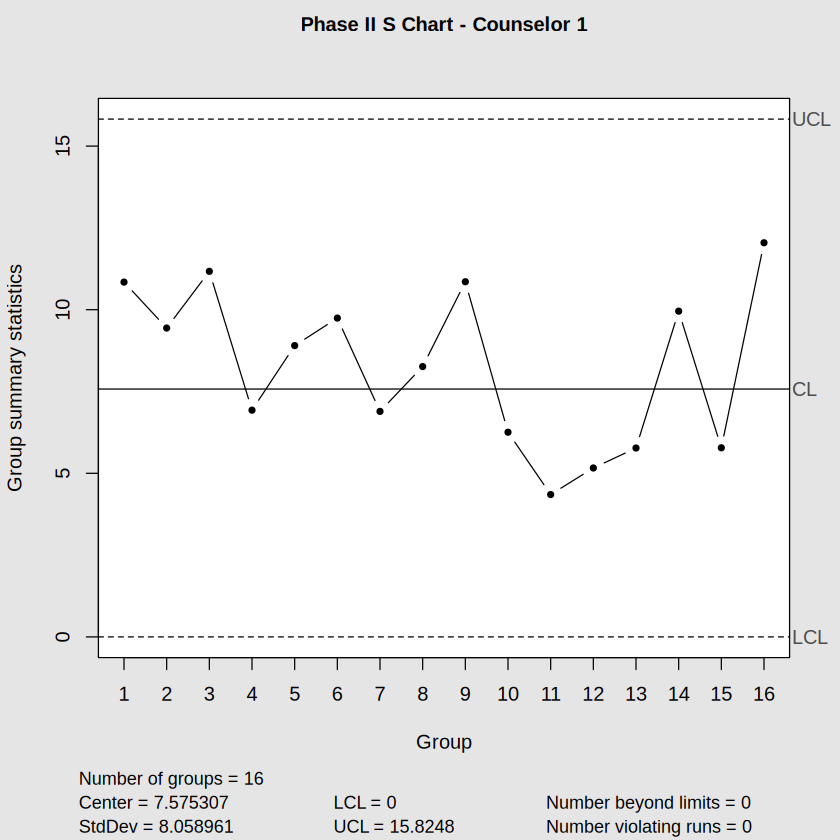

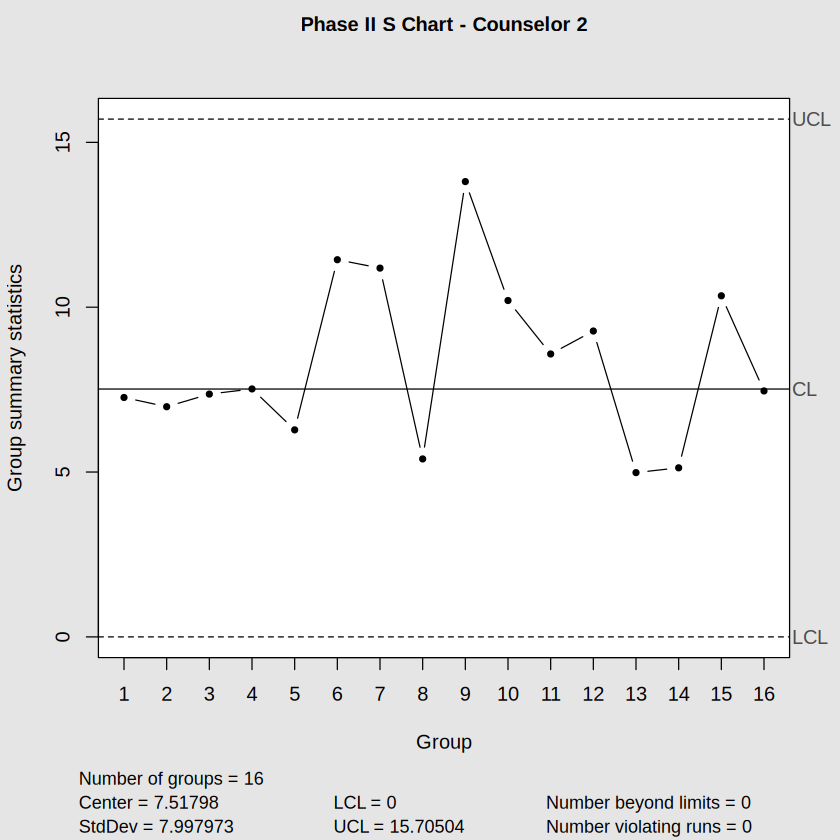

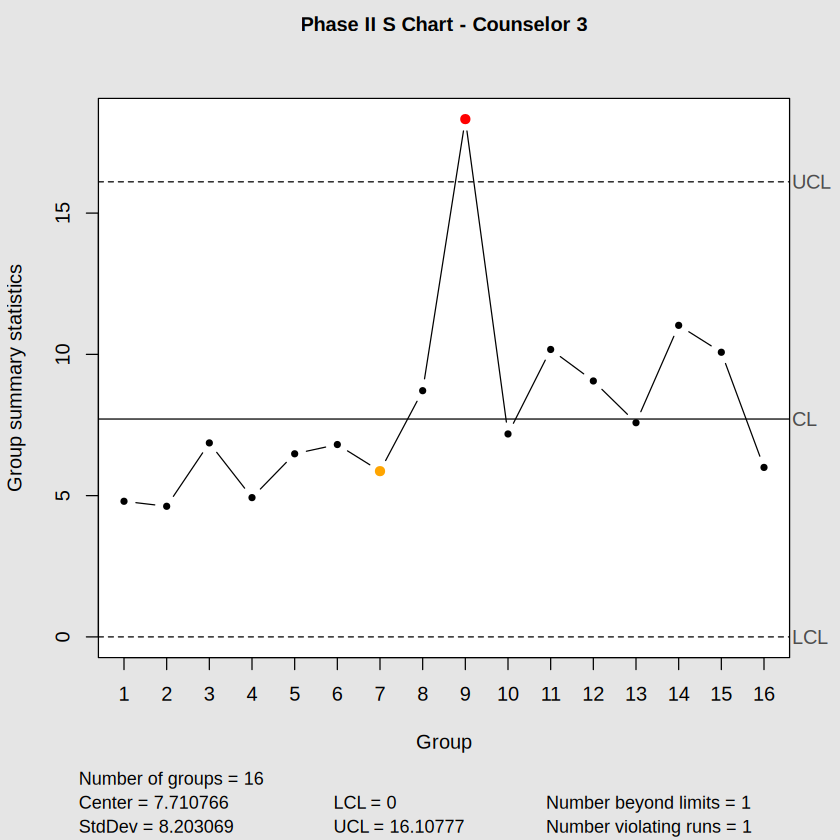

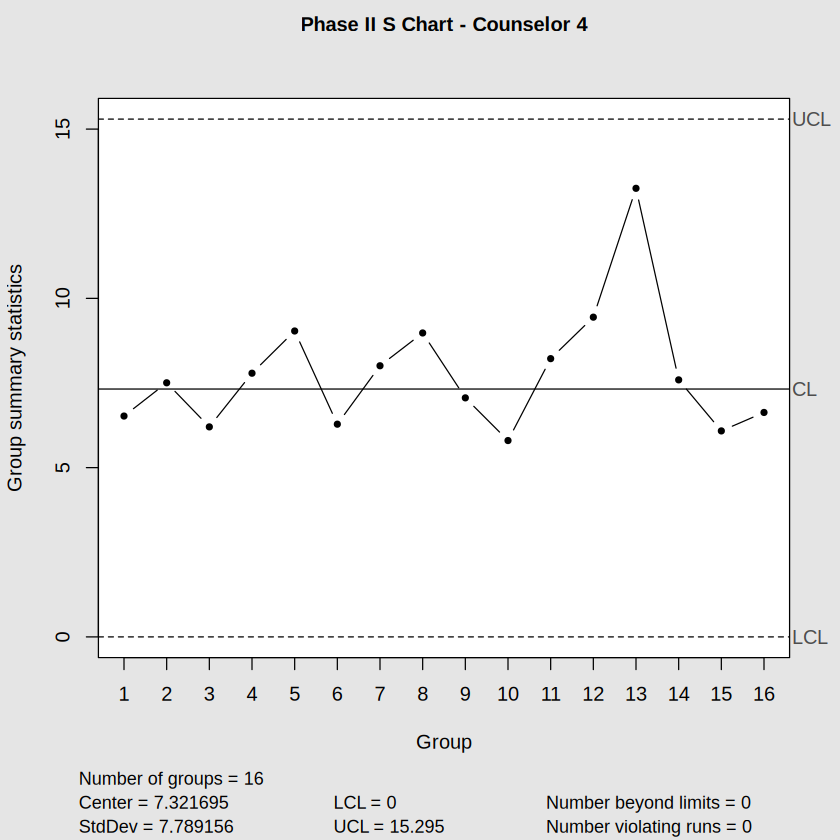

In [29]:
# S chart
for (i in 1:4) {
qcc(
  phase2[[i]],
  type = "S",
  center = phase1_s_centers[i],
  std.dev = phase1_sds[i],
  title = paste("Phase II S Chart - Counselor", i)
)
}

#Q6
These charts point to Counselor 3. Their mean scores exceed the upper limit in weeks 1, 2, 4, 5, 8, 9, 11, 12, 13, 14 and 15. Their standard deviation also exceeds its upper limit in week 9, meaning that week’s scores were unusually spread out. Counselors 1, 2 and 4 have no points outside their individual limits.

### Q7: What is the benefit of using a multivariate control chart over several separate univariate control charts? What is one limitation?

A multivariate chart considers how the counselors’ scores are related. It can catch an unusual combination of scores that separate charts might miss, even when no individual score crosses its limit.

One limitation is that it tells us something has changed, but it doesn’t tell us which counselor is responsible for the signal. We need separate charts to investigate that.

## Improve

### Q8: Based on your findings in Q6, briefly describe what intervention(s) you, as the director, might reasonably take regarding the counselor(s) flagged as out of control.

I would meet with Counselor 3 to review the flagged weeks and discuss what might explain the higher scores, such as a heavier workload or clients with more complex needs. Based on that review, I would provide additional supervision, case consultation, or training as needed. I would also review whether any clients need additional support and continue monitoring the scores to see whether the pattern improve

## Control

### Q9: It is reasonable to assume that this same monitoring situation could also be conceptualized as a **multiple stream process (MSP)** -- that is, treating the four counselors as independent, parallel processes rather than a single correlated multivariate one. Perform the same Phase I analysis as before, but using the Control Chart for Each Stream MSP technique ($L = 3.46$). Do we have evidence of statistical control?

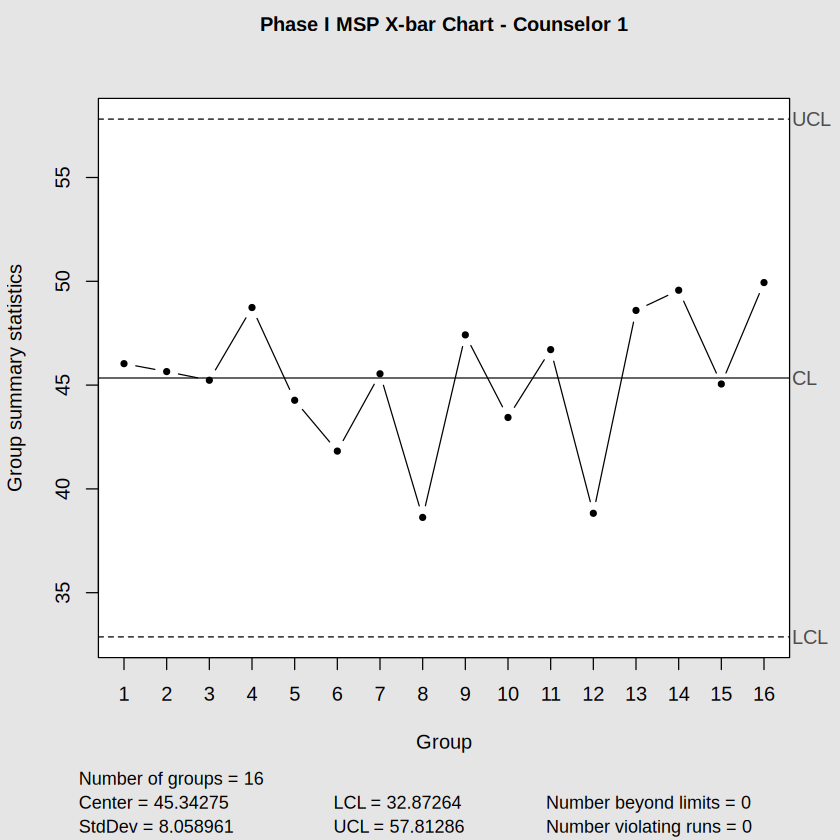

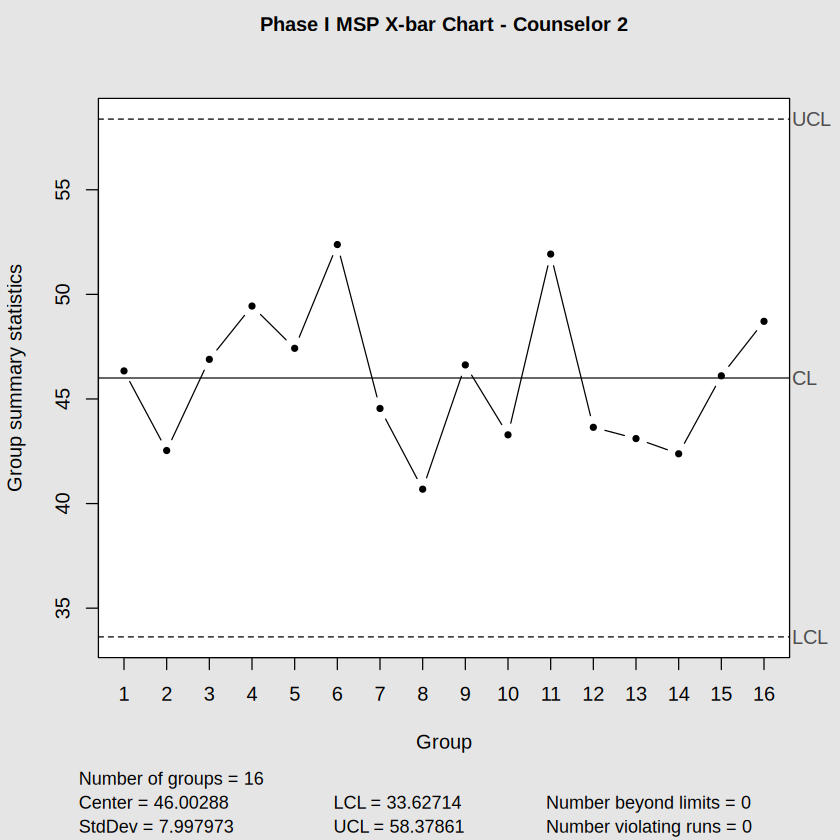

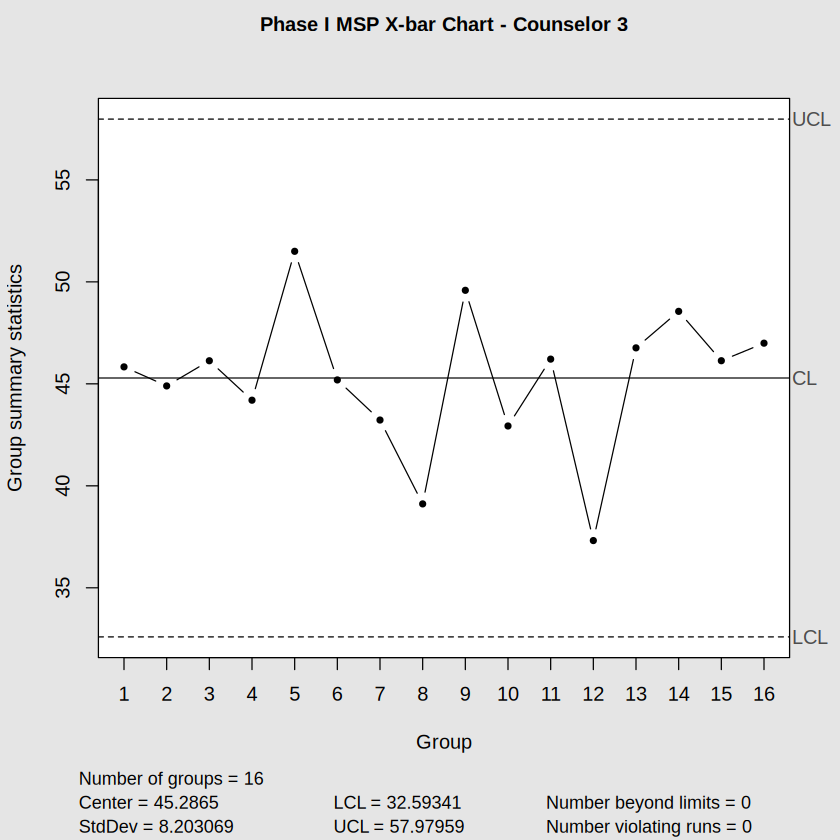

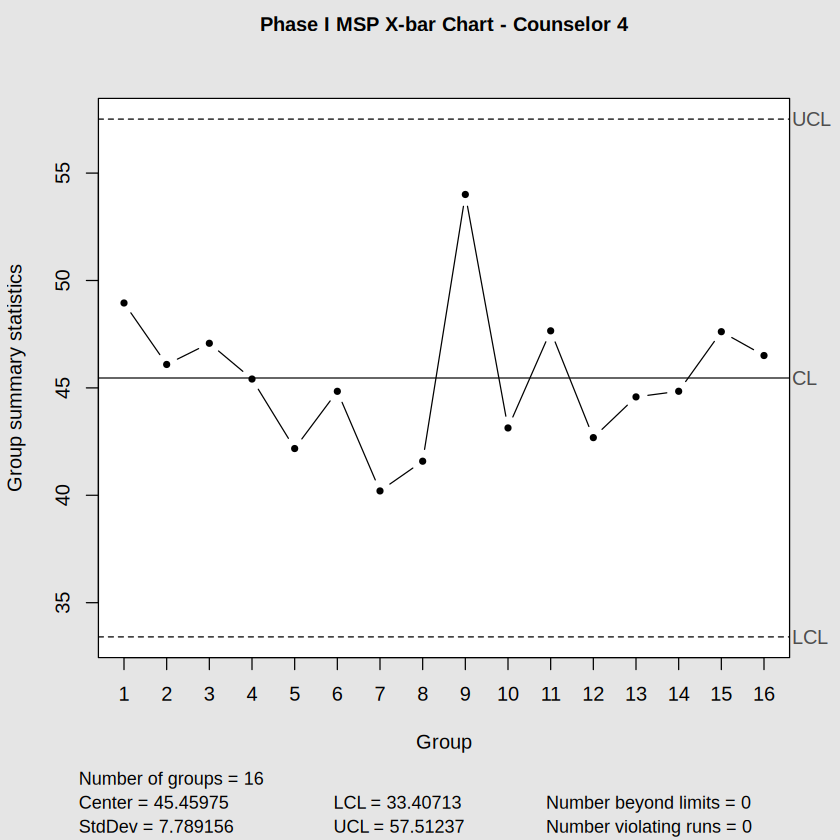

In [31]:
## Q9 Code ##
for (i in 1:4) {

  # Phase I X-bar chart
  qcc(
    phase1[[i]],
    type = "xbar",
    center = phase1_means[i],
    std.dev = phase1_sds[i],
    nsigmas = 3.46,
    title = paste("Phase I MSP X-bar Chart - Counselor", i)
  )


}

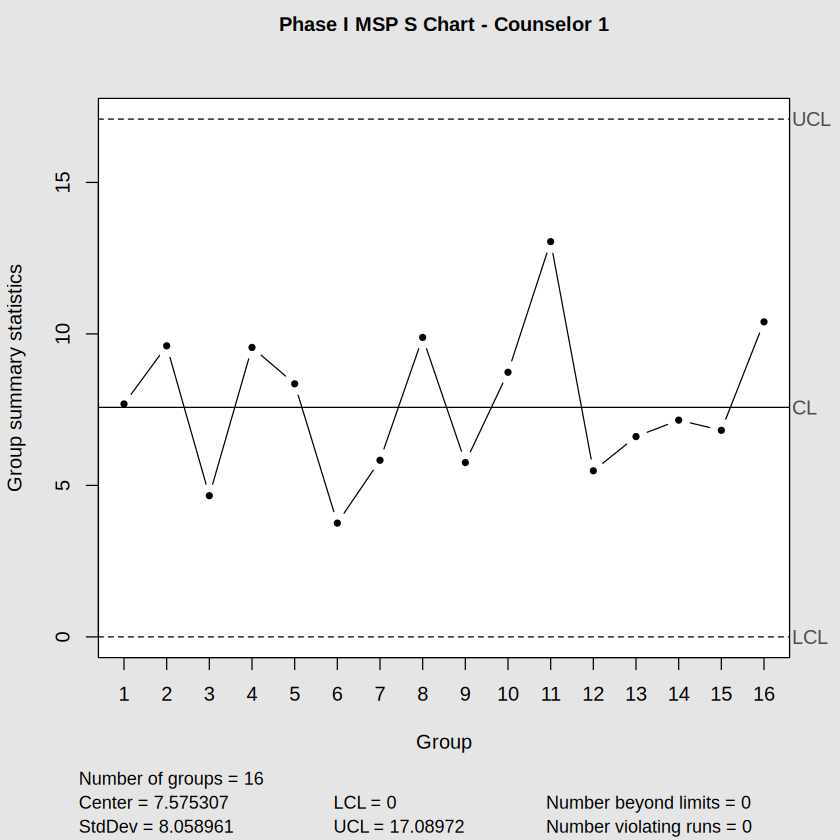

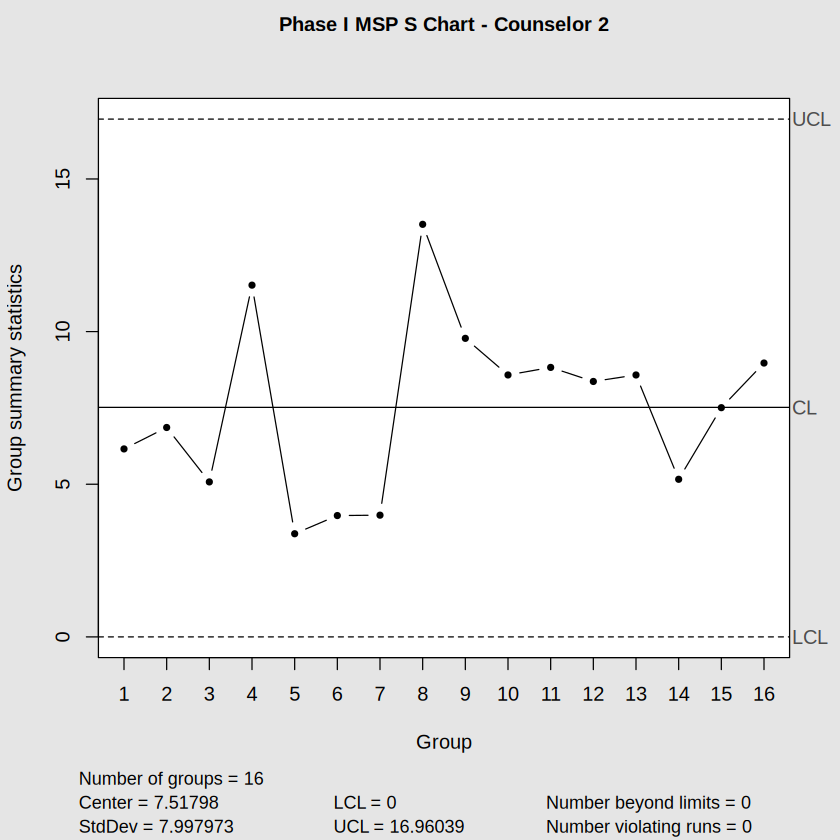

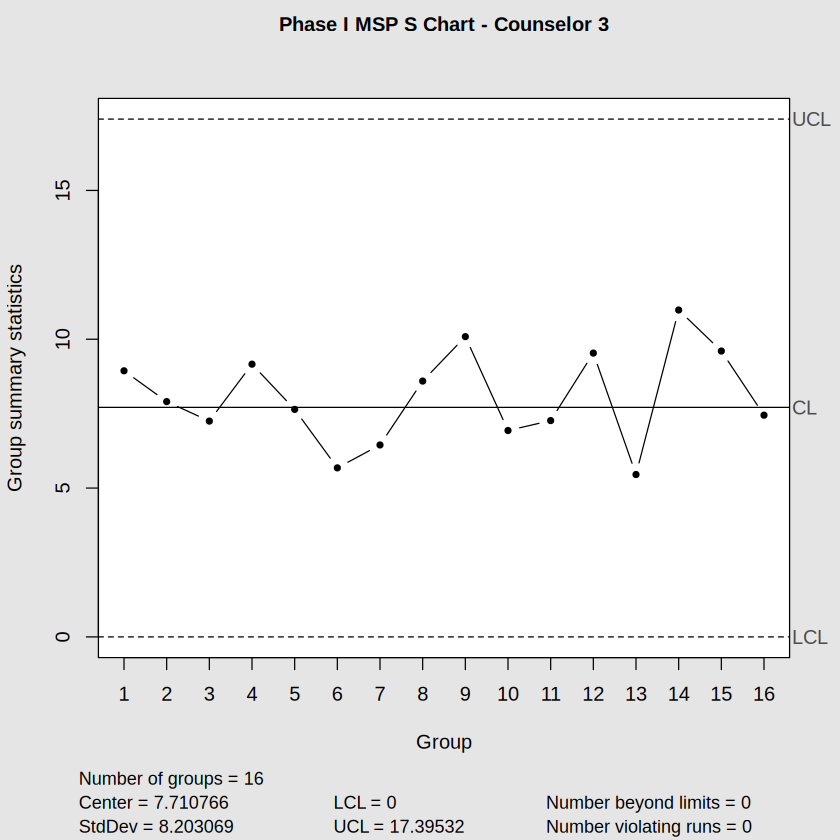

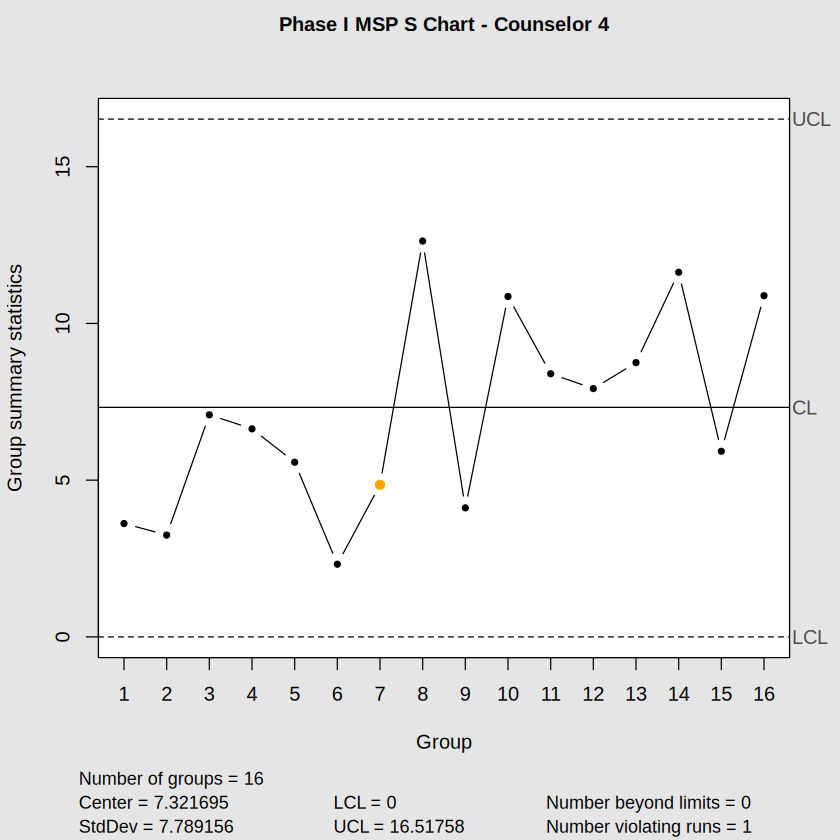

In [32]:
  # Phase I S chart
  for (i in 1:4) {
    qcc(
    phase1[[i]],
    type = "S",
    center = phase1_s_centers[i],
    std.dev = phase1_sds[i],
    nsigmas = 3.46,
    title = paste("Phase I MSP S Chart - Counselor", i)
  )
  }

Yes, Phase I appears to be in statistical control under the MSP approach. None of the weekly means or standard deviations falls outside the control limits for any counselor. Based on these charts, we have no evidence of an unusual change during the fall semester.

### Q10: Perform Phase II analysis using the Control Chart for Each Stream MSP technique. Do we still have evidence of statistical control? If not, which stream(s) (i.e., counselors) may be causing the out-of-control point(s)?

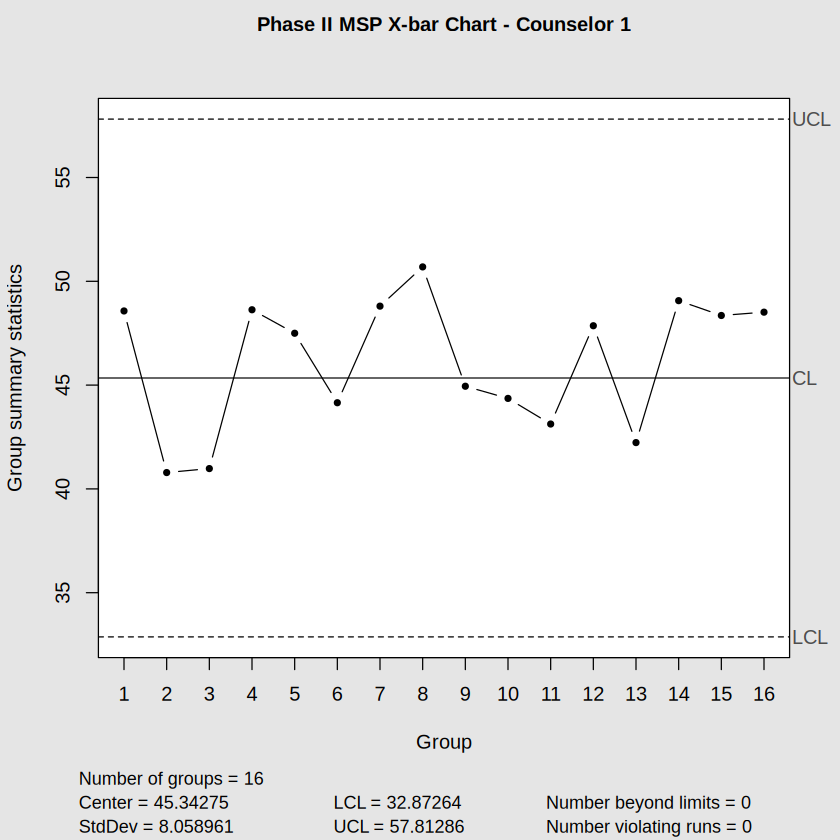

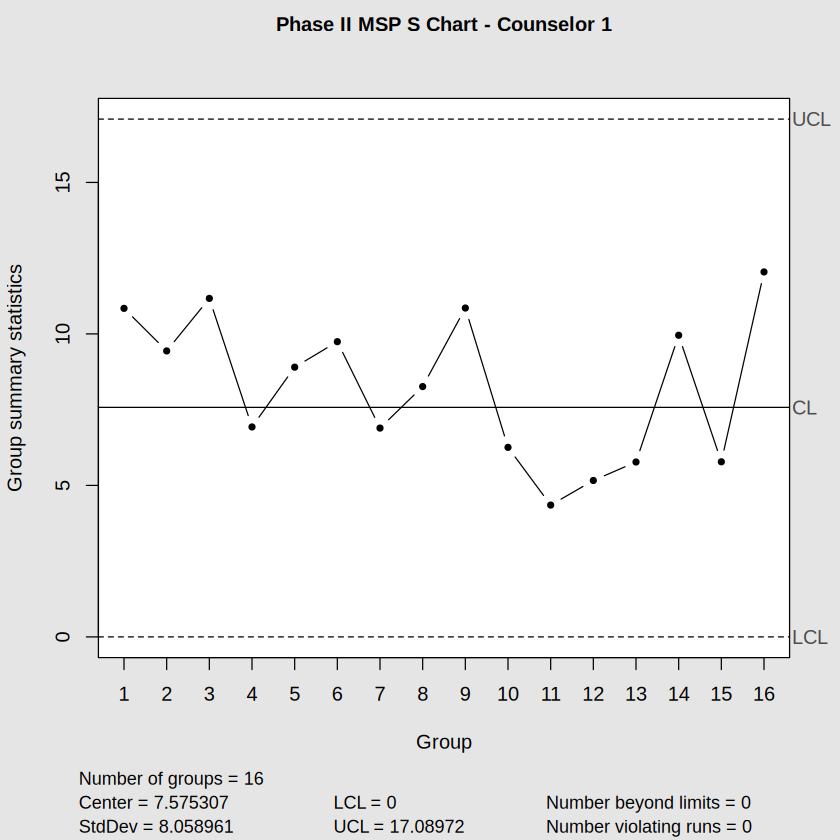

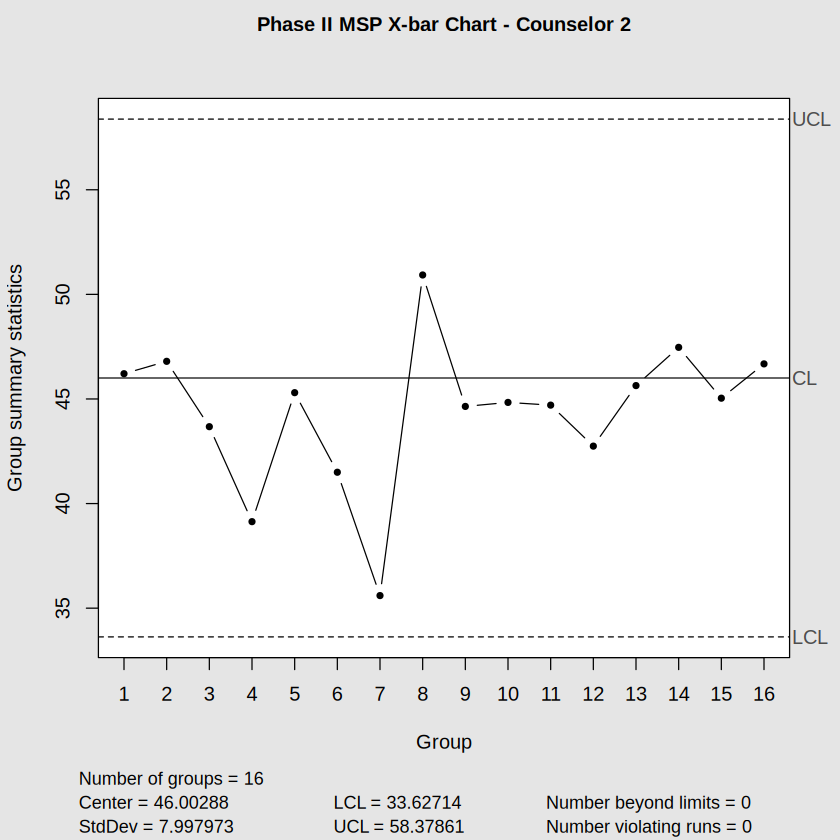

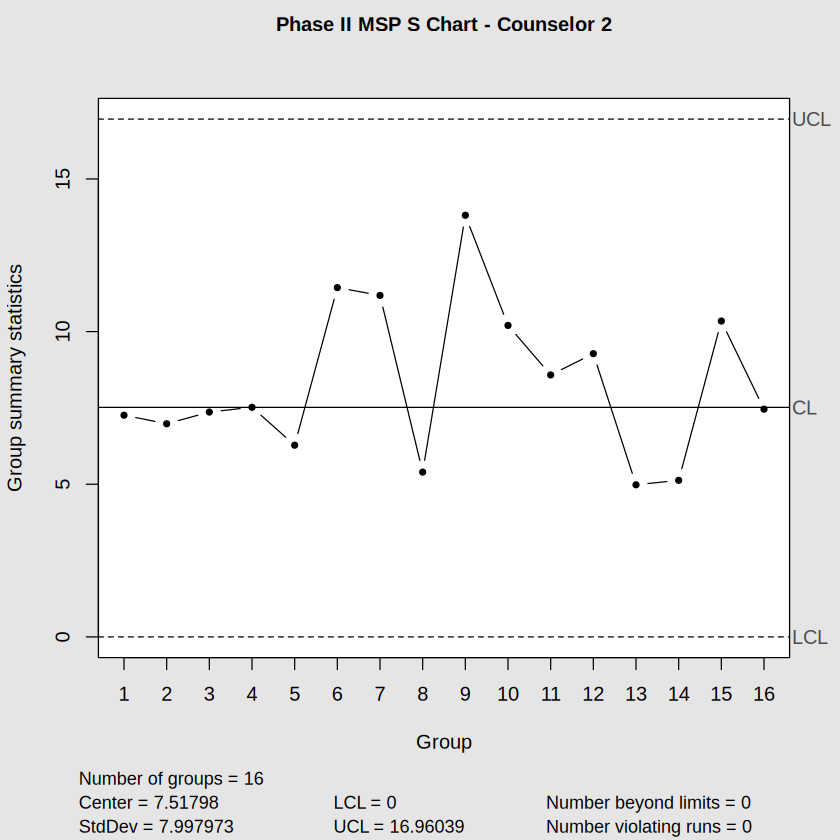

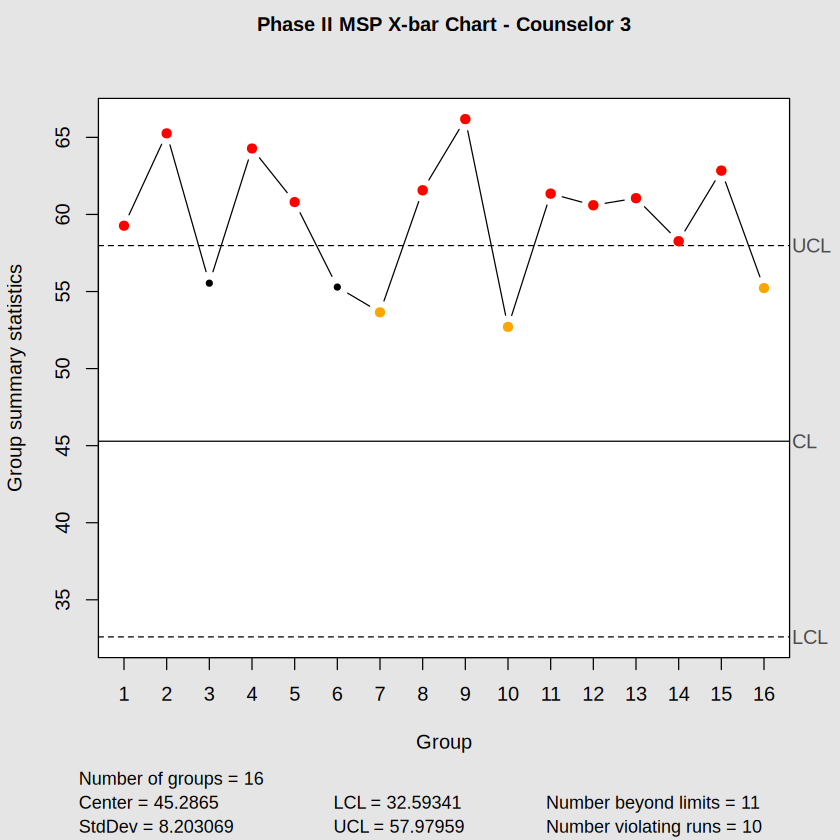

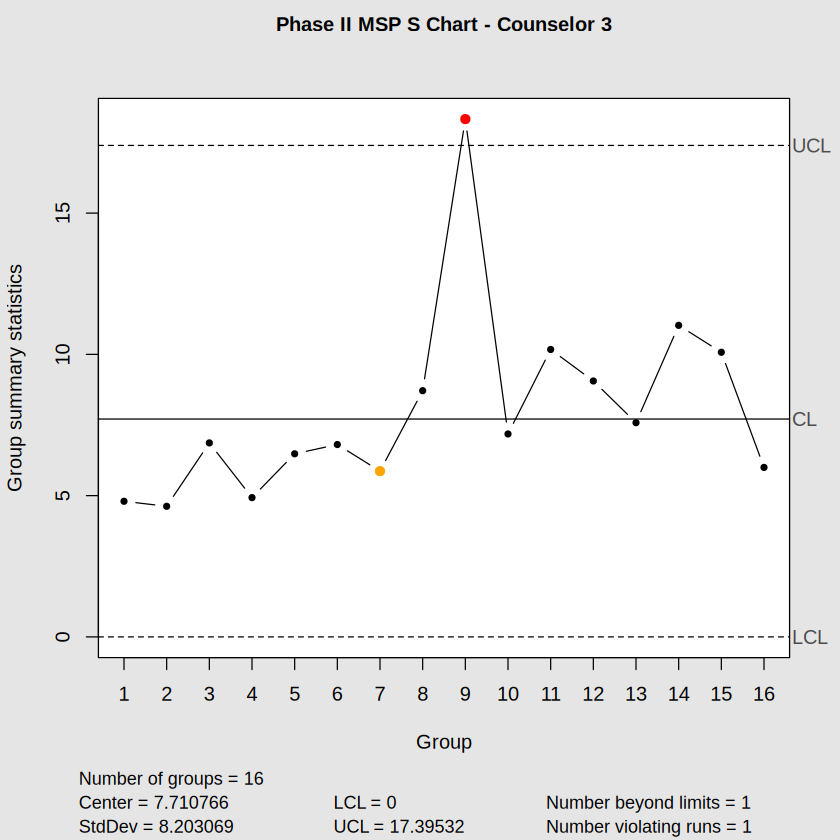

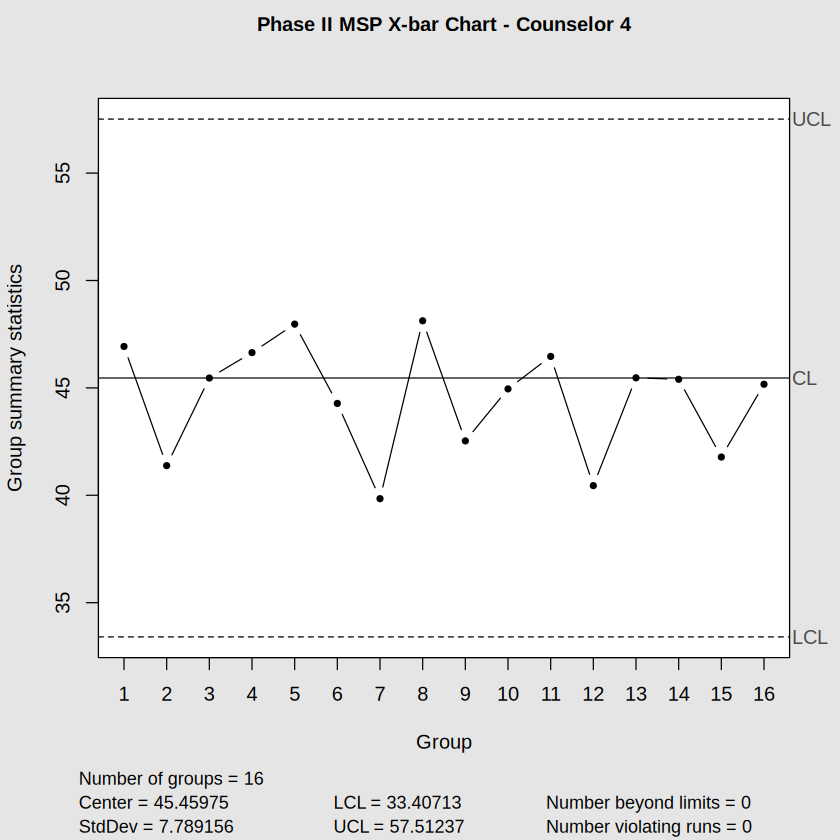

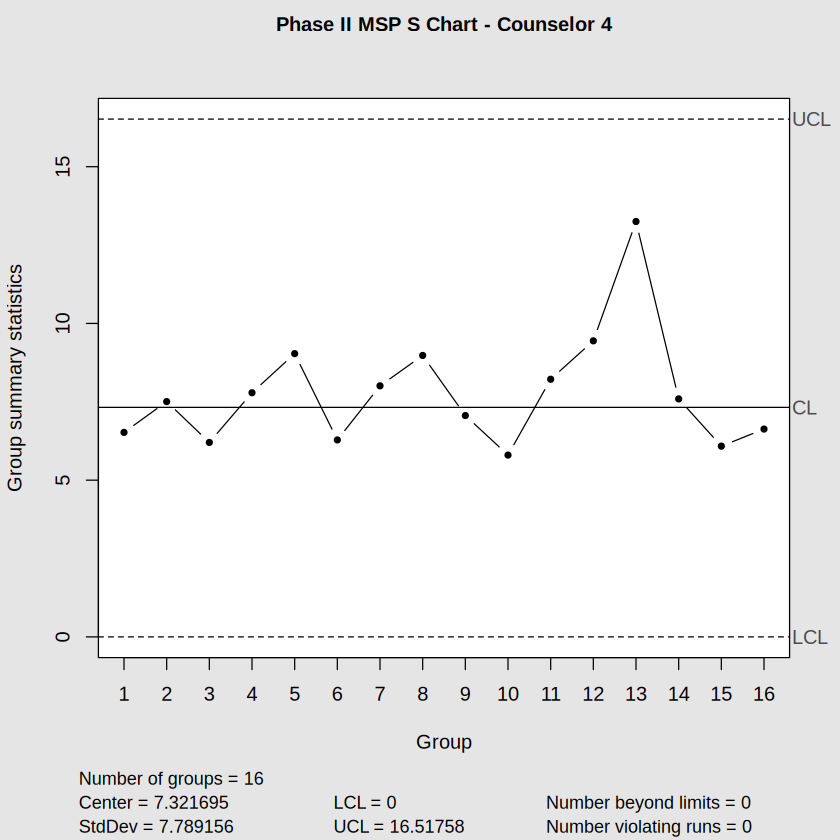

In [34]:
## Q10 Code ##
for (i in 1:4) {

  # Phase II X-bar chart
  qcc(
    phase2[[i]],
    type = "xbar",
    center = phase1_means[i],
    std.dev = phase1_sds[i],
    nsigmas = 3.46,
    title = paste("Phase II MSP X-bar Chart - Counselor", i)
  )

  # Phase II S chart
  qcc(
    phase2[[i]],
    type = "S",
    center = phase1_s_centers[i],
    std.dev = phase1_sds[i],
    nsigmas = 3.46,
    title = paste("Phase II MSP S Chart - Counselor", i)
  )
}

No, the process no longer appears to be in statistical control. Counselor 3’s weekly means exceed the upper limit in weeks 1, 2, 4, 5, 8, 9, 11, 12, 13, 14 and 15. Their S chart also exceeds its upper limit in week 9, showing unusually high variation that week.

Counselors 1, 2 and 4 have no points outside their limits, so Counselor 3 is the stream that needs further investigation.

### Q11: What is a difference between a multivariate process and a multiple stream process? Given what you found in Q4-Q10, which framing do you think is the more defensible choice for this specific scenario, and why?

A multivariate process treats the counselors scores as related and monitors them together. A multiple stream process treats the counselors as independent, parallel streams and monitors each one separately.

 I think the **multivariate** approach makes more sense. The Phase I data show positive relationships between counselors scores, and shared factors like exam stress could affect several counselors at once. Both approaches flagged Counselor 3, but the multivariate chart accounts for those relationships. The separate charts are still useful for figuring out which counselor needs attention.

### Q12: Provide an overview of your results that you, as the director, could bring to the university's Vice President of Student Affairs. What is the current status of The Owl's Nest program, and what actions (if any) have you taken or would you recommend?

The Owls Nest program appeared stable in Phase I, but Phase II showed higher symptom scores among Counselor 3 clients. Both monitoring approaches flagged this change, and week 9 also showed unusually high variation. The charts did not flag similar changes for the other counselors.

I would review Counselor 3 cases to understand what might explain the increase, including changes in client needs or workload. I would recommend additional supervision where needed and review whether any clients need a higher level of care. I would also continue monitoring the program to see whether the pattern improves.